# Trabajo Práctico 3: Aprendizaje No Supervisado

### Realizado por: Sofía Quiroz Valencia 


## Introducción

El aprendizaje no supervisado permite identificar patrones y estructuras dentro de un conjunto de datos sin necesidad de contar con categorías previamente establecidas.

En este trabajo se utilizará el conjunto de datos **Wholesale Customers**, que contiene información sobre el comportamiento de compra de clientes de un distribuidor mayorista, considerando diferentes categorías de productos.

A partir de esta información, se aplicarán técnicas de reducción de dimensionalidad y agrupamiento para explorar las relaciones entre las variables e identificar posibles segmentos de clientes con comportamientos de consumo similares.

Para ello, se utilizarán tres enfoques: el conjunto de datos original, la reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA) y la selección de variables a partir de su correlación. Posteriormente, se aplicará el algoritmo K-means para comparar los resultados obtenidos.

## Objetivo

Analizar los patrones de consumo de los clientes de un distribuidor mayorista mediante técnicas de aprendizaje no supervisado, comparando diferentes enfoques de reducción de dimensionalidad y agrupamiento.

## Pregunta de investigación

¿Es posible identificar grupos de clientes con comportamientos de compra similares mediante PCA, selección de variables y el algoritmo K-means?

## ¿Qué buscamos encontrar?

Se busca identificar qué características explican mejor las diferencias entre los clientes, reconocer posibles grupos de consumo y determinar cuál de los tres enfoques permite obtener agrupamientos de mejor calidad.

## Dataset 
**Wholesale Customers**: Esta base de datos contiene información sobre las compras anuales de 440 clientes de un distribuidor mayorista. Los registros muestran el gasto realizado en diferentes categorías de productos, lo que permite estudiar las diferencias en sus patrones de consumo.

El conjunto de datos cuenta con seis variables numéricas principales que serán utilizadas en el análisis. Las variables categóricas relacionadas con el canal de distribución y la región se conservarán únicamente como información adicional y no participarán en los modelos de agrupamiento.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Cargar la base de datos


In [4]:
# Cargar el archivo 
df = pd.read_csv("C:/Documentos/OCTAVO SEMESTRE/Ciencia de Datos II/Datasets/Wholesale customers data.csv")

# Mostrar las primeras filas
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Revisión de estructura 

In [5]:
# Dimensiones del dataset
print("Dimensiones:", df.shape)

# Información general
df.info()

# Verificar valores faltantes
print("\nValores faltantes:")
print(df.isnull().sum())

# Estadísticas descriptivas
display(df.describe())

Dimensiones: (440, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Valores faltantes:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### Descripción de las variables seleccionadas

Para el análisis se seleccionaron seis variables numéricas que representan el gasto anual de los clientes en diferentes categorías de productos:

| Variable | Descripción | Relevancia para el análisis |
|---|---|---|
| Fresh | Gasto anual en productos frescos. | Permite identificar clientes con mayor consumo de alimentos frescos. |
| Milk | Gasto anual en productos lácteos. | Ayuda a reconocer diferencias en la demanda de productos lácteos. |
| Grocery | Gasto anual en abarrotes. | Permite analizar el consumo de productos de mercado. |
| Frozen | Gasto anual en productos congelados. | Identifica diferencias en los hábitos de compra de congelados. |
| Detergents_Paper | Gasto anual en detergentes y productos de papel. | Permite reconocer patrones de compra de productos de limpieza y uso cotidiano. |
| Delicassen | Gasto anual en productos delicatessen. | Ayuda a identificar diferencias en el consumo de productos especializados. |

Estas variables son relevantes porque permiten comparar los hábitos de compra de los clientes y encontrar similitudes o diferencias en sus patrones de consumo. Además, al ser variables numéricas, pueden utilizarse en técnicas como PCA y K-means.

In [9]:
variables = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[variables]

display(X.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


### Estandarización de las variables

Las variables presentan diferentes niveles de gasto y escalas de valores. Por esta razón, se utiliza `StandardScaler`, que transforma los datos para que tengan una media cercana a cero y una desviación estándar cercana a uno.

Este procedimiento evita que las variables con valores numéricos más grandes tengan una influencia desproporcionada en los resultados de PCA y K-means.

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convertir nuevamente a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=variables)

display(X_scaled.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


Al aplicar `StandardScaler`, las seis variables fueron transformadas para que tengan una media cercana a cero y una desviación estándar de uno.

Al comparar los datos originales con los estandarizados, se observa que los valores ahora se encuentran expresados en una escala común. Los valores positivos indican que el gasto del cliente está por encima del promedio de la variable, mientras que los negativos representan valores inferiores al promedio.

Este procedimiento es importante porque las categorías de productos presentan diferencias considerables en sus niveles de gasto. De esta manera, se evita que las variables con valores numéricos más grandes tengan mayor influencia en los resultados de PCA y K-means.

### Reducción de dimensionalidad mediante PCA

El Análisis de Componentes Principales (PCA) permite reducir la cantidad de variables de un conjunto de datos, transformándolas en nuevas dimensiones que resumen la información original.

En este trabajo se aplicará PCA sobre las seis variables previamente estandarizadas, con el propósito de identificar cuáles componentes explican una mayor proporción de la variabilidad de los datos.

Posteriormente, se utilizarán las dos primeras componentes principales para representar gráficamente a los clientes y explorar posibles patrones de agrupamiento.

In [10]:
# Aplicar PCA sobre las seis variables estandarizadas
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

# Porcentaje de varianza explicada
varianza = pca.explained_variance_ratio_ * 100

print("Varianza explicada por cada componente:")
for i, valor in enumerate(varianza):
    print(f"Componente {i+1}: {valor:.2f}%")

Varianza explicada por cada componente:
Componente 1: 44.08%
Componente 2: 28.38%
Componente 3: 12.33%
Componente 4: 9.40%
Componente 5: 4.76%
Componente 6: 1.05%


Los resultados muestran que la primera componente principal explica el 44,08 % de la variabilidad de los datos, mientras que la segunda explica el 28,38 %. En conjunto, ambas componentes representan el 72,46 % de la información original.

Por su parte, los cuatro componentes restantes explican porcentajes menores de variabilidad. Esto indica que una parte importante de la información puede resumirse utilizando los dos primeras componentes principales.

Por lo tanto, reducir las seis variables originales a dos componentes permite simplificar el análisis, conservando una proporción considerable de la información.

### Varianza explicada por las componentes principales

Se construye un gráfico de sedimentación (scree plot) para observar el porcentaje de varianza explicado por cada componente principal.

Este gráfico permite identificar cuántas componentes concentran una mayor proporción de la información del conjunto de datos y evaluar la conveniencia de reducir las seis variables originales.

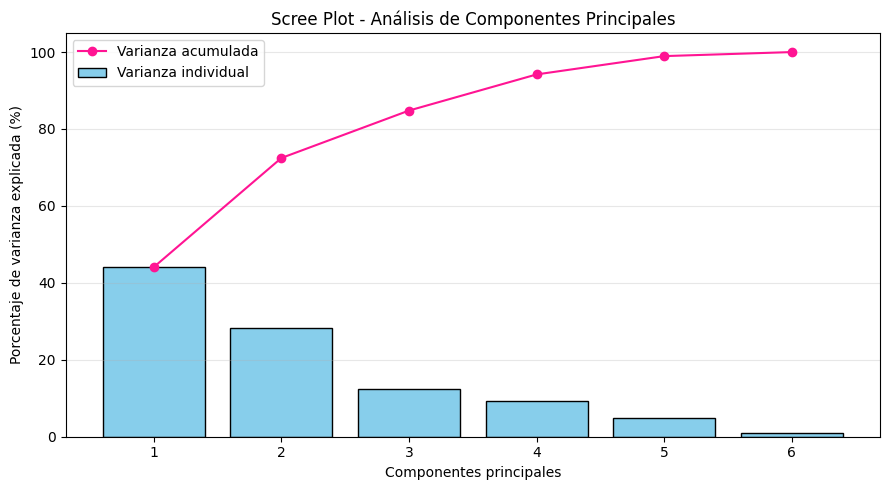

In [11]:
# Crear gráfico de varianza explicada
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, 7),
    varianza,
    color="skyblue",
    edgecolor="black",
    label="Varianza individual"
)

plt.plot(
    range(1, 7),
    np.cumsum(varianza),
    marker="o",
    color="deeppink",
    label="Varianza acumulada"
)

plt.xlabel("Componentes principales")
plt.ylabel("Porcentaje de varianza explicada (%)")
plt.title("Scree Plot - Análisis de Componentes Principales")
plt.xticks(range(1, 7))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El gráfico muestra que las primeras componentes principales concentran la mayor proporción de variabilidad. Se observa una disminución progresiva en la varianza explicada por cada componente, siendo las dos primeras las que aportan mayor información.

La línea de varianza acumulada permite observar cómo se alcanza aproximadamente el 72,46 % con las dos primeras componentes y el 100 % al considerar las seis.

Esto respalda la decisión de utilizar dos componentes principales para facilitar la representación y el análisis de los datos.

### Reducción a dos componentes principales

A partir del análisis anterior, se seleccionan las dos primeras componentes principales para representar los datos en un espacio de dos dimensiones.

Esta transformación permite trabajar con una versión reducida del conjunto de datos, facilitando su visualización y la identificación de posibles patrones entre los clientes.

In [12]:
# Reducir los datos a dos componentes
pca_2 = PCA(n_components=2)

X_pca_2 = pca_2.fit_transform(X_scaled)

# Crear DataFrame con las dos componentes
df_pca = pd.DataFrame(
    X_pca_2,
    columns=["Componente 1", "Componente 2"]
)

display(df_pca.head())

# Varianza acumulada de las dos componentes
print(
    "Varianza explicada por las dos componentes:",
    round(pca_2.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

,Componente 1,Componente 2
0,0.193291,-0.305100
1,0.434420,-0.328413
2,0.811143,0.815096
3,-0.778648,0.652754
4,0.166287,1.271434


Varianza explicada por las dos componentes: 72.46 %


### Representación de los datos mediante PCA

Se realiza un diagrama de dispersión utilizando las dos primeras componentes principales. Cada punto representa un cliente y su ubicación depende de las características de consumo que presenta.

La visualización permite explorar si existen agrupaciones, concentraciones o diferencias entre los clientes, sin establecer previamente categorías.

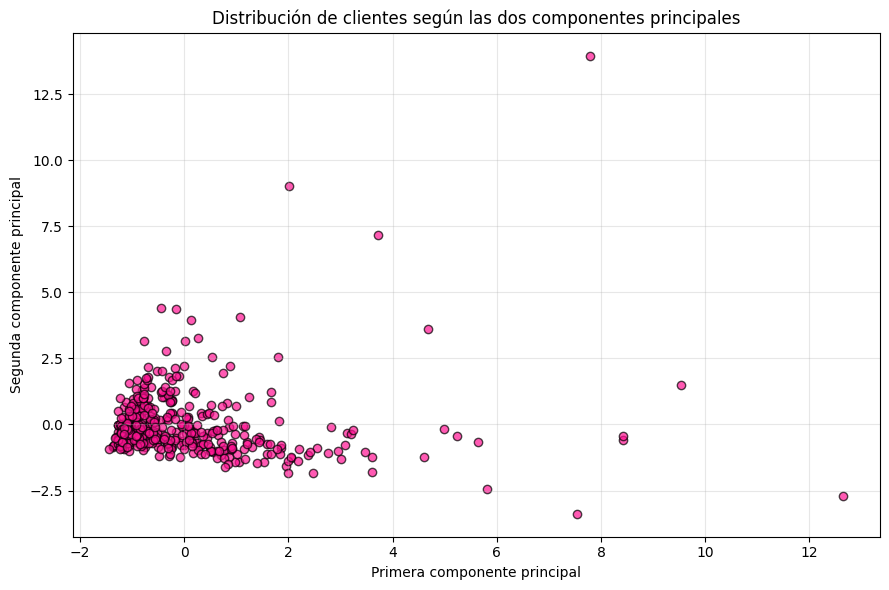

In [13]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_pca["Componente 1"],
    df_pca["Componente 2"],
    alpha=0.7,
    color="deeppink",
    edgecolor="black"
)

plt.xlabel("Primera componente principal")
plt.ylabel("Segunda componente principal")
plt.title("Distribución de clientes según las dos componentes principales")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Al representar los clientes mediante los dos primeras componentes principales, que explican conjuntamente el 72,46 % de la variabilidad, se observa que la mayoría de las observaciones se concentra cerca del origen, lo que sugiere similitudes en sus patrones de consumo. Sin embargo, existen algunos clientes considerablemente alejados de esta concentración, que podrían presentar comportamientos diferenciados. Aunque no se identifican grupos claramente separados, esta representación permite explorar posibles segmentos de clientes mediante la aplicación del algoritmo K-means.

### Conclusión de PCA

La aplicación de PCA permitió reducir las seis variables originales a dos componentes principales, que explican conjuntamente el 72,46 % de la variabilidad de los datos.

Esta reducción facilita la visualización de los patrones de consumo y permite trabajar con una representación más sencilla de los clientes. No obstante, para determinar si esta transformación permite obtener agrupamientos de buena calidad, se compararán sus resultados con los obtenidos mediante K-means sobre los datos originales y los datos seleccionados por correlación.

## Selección de variables

En esta etapa se realizará una selección de variables mediante el análisis de correlación de Pearson, con el propósito de identificar relaciones fuertes entre las características del conjunto de datos.

Cuando dos variables presentan una correlación elevada, pueden contener información similar. Por esta razón, se evaluará la posibilidad de eliminar alguna de ellas y reducir la cantidad de características utilizadas en el análisis.

Se tomará como referencia una correlación superior a 0,85 para identificar posibles variables redundantes.

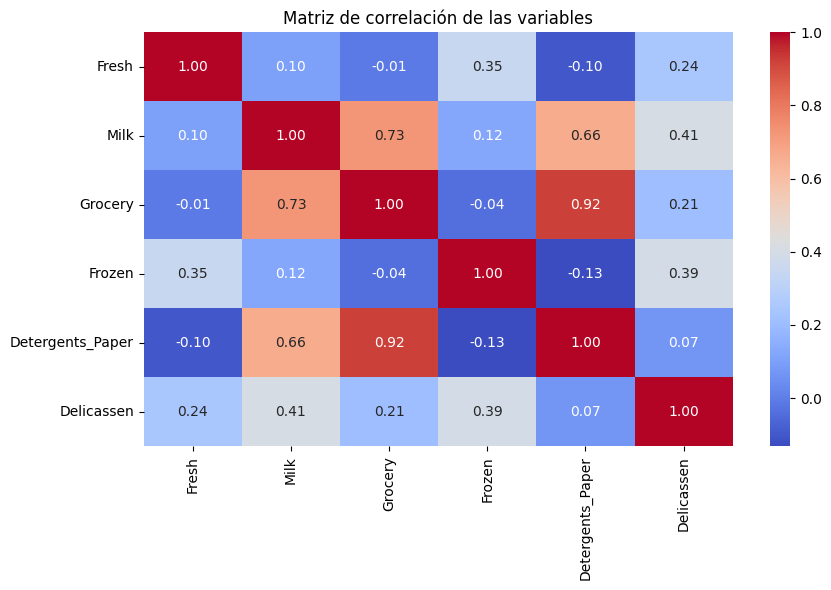

In [14]:
# Calcular la matriz de correlación
correlacion = X.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de las variables")
plt.tight_layout()
plt.show()

### Identificación de variables redundantes

A partir de la matriz de correlación, se identificarán las parejas de variables que presentan una relación positiva o negativa elevada.

Se utilizará el valor absoluto de la correlación para evaluar la intensidad de la relación, independientemente de su dirección. Cuando dos variables superen el umbral establecido de 0,85, se considerará eliminar una de ellas, teniendo en cuenta su relevancia para el análisis.

In [19]:
correlacion_superior = correlacion.abs()

pares = []

for i in range(len(correlacion.columns)):
    for j in range(i):
        valor = correlacion_superior.iloc[i, j]

        if valor > 0.85:
            pares.append((
                correlacion.columns[i],
                correlacion.columns[j],
                round(valor, 3)
            ))

print("Variables con correlación superior a 0.85:")

for par in pares:
    print(par)

Variables con correlación superior a 0.85:
('Detergents_Paper', 'Grocery', np.float64(0.925))


`Grocery` y `Detergents_Paper` presentan una correlación positiva muy alta de 0.925. Es decir, ambas variables tienen un comportamiento bastante similar dentro del conjunto de datos.

Debido a esta relación, se decidió eliminar `Detergents_Paper` y conservar `Grocery`, con el fin de reducir la redundancia y mantener una menor cantidad de características para el análisis.

De esta manera, se pasó de seis a cinco variables, conservando las características Fresh, Milk, Grocery, Frozen y Delicassen.

### Creación del nuevo conjunto de datos

In [20]:
variables_seleccionadas = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Delicassen"
]

X_seleccion = X[variables_seleccionadas]

# Estandarizar las variables seleccionadas
scaler_seleccion = StandardScaler()
X_seleccion_scaled = scaler_seleccion.fit_transform(X_seleccion)

print("Variables seleccionadas:", variables_seleccionadas)
print("Cantidad de variables:", len(variables_seleccionadas))

Variables seleccionadas: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Delicassen']
Cantidad de variables: 5


## Agrupamiento y comparación de resultados

En esta etapa se aplicará el algoritmo K-means para identificar grupos de clientes con comportamientos de compra similares.

El algoritmo se ejecutará sobre tres versiones de los datos:

1. **Datos originales:** las seis variables numéricas estandarizadas.
2. **Datos reducidos mediante PCA:** las dos primeras componentes principales.
3. **Datos con selección de variables:** las características conservadas después del análisis de correlación: Fresh, Milk, Grocery, Frozen y Delicassen.

Para cada enfoque se probarán valores de K entre 2 y 6, con el propósito de comparar la calidad de los agrupamientos obtenidos.

In [21]:
# Definir los tres conjuntos de datos
conjuntos = {
    "Original": X_scaled,
    "PCA (2 componentes)": X_pca_2,
    "Selección de variables": X_seleccion_scaled
}

# Valores de K que se van a evaluar
valores_k = range(2, 7)

### Evaluación de los modelos

Para evaluar los resultados de K-means se utilizarán el método del codo y el coeficiente Silhouette.

El método del codo permite observar cómo cambia la inercia al aumentar el número de grupos. Por su parte, el Silhouette Score permite evaluar la calidad de los agrupamientos, considerando la cercanía de las observaciones dentro de cada grupo y su separación respecto a los demás.

Se probarán cinco valores de K, desde 2 hasta 6, para comparar el comportamiento de los tres enfoques.

In [22]:
# Guardar los resultados
resultados = []

for nombre, datos in conjuntos.items():

    for k in valores_k:

        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        grupos = modelo.fit_predict(datos)

        # Calcular Silhouette Score
        silueta = silhouette_score(datos, grupos)

        resultados.append({
            "Enfoque": nombre,
            "K": k,
            "Inercia": modelo.inertia_,
            "Silhouette Score": silueta
        })

# Crear tabla de resultados
tabla_resultados = pd.DataFrame(resultados)

display(tabla_resultados.round(4))

,Enfoque,K,Inercia,Silhouette Score
0,Original,2,1956.1243,0.5472
1,Original,3,1608.4311,0.5483
2,Original,4,1317.8384,0.3485
3,Original,5,1058.7713,0.3690
4,Original,6,915.7413,0.3782
5,PCA (2 componentes),2,1227.8740,0.6362
6,PCA (2 componentes),3,891.0123,0.6267
7,PCA (2 componentes),4,612.8120,0.4888
8,PCA (2 componentes),5,429.0124,0.4877
9,PCA (2 componentes),6,347.0767,0.4594


### Análisis comparativo de los resultados

Los resultados muestran que el enfoque PCA obtuvo el mejor agrupamiento, con un Silhouette Score de 0.6362 para K = 2. Le sigue la selección de variables, con 0.6277, mientras que los datos originales alcanzaron 0.5483 para K = 3.

Estos resultados indican que la reducción de dimensionalidad y la selección de variables permiten obtener grupos mejor diferenciados. Por tanto, PCA con dos componentes y dos grupos presenta el mejor desempeño entre los enfoques evaluados.

### Método del codo

Se presentan los resultados de la inercia para cada uno de los enfoques. Estos gráficos permiten observar cómo cambia la variabilidad interna de los grupos a medida que aumenta el número de agrupamientos.

El objetivo es identificar un posible punto de inflexión en cada gráfico, que permita seleccionar un número adecuado de grupos.

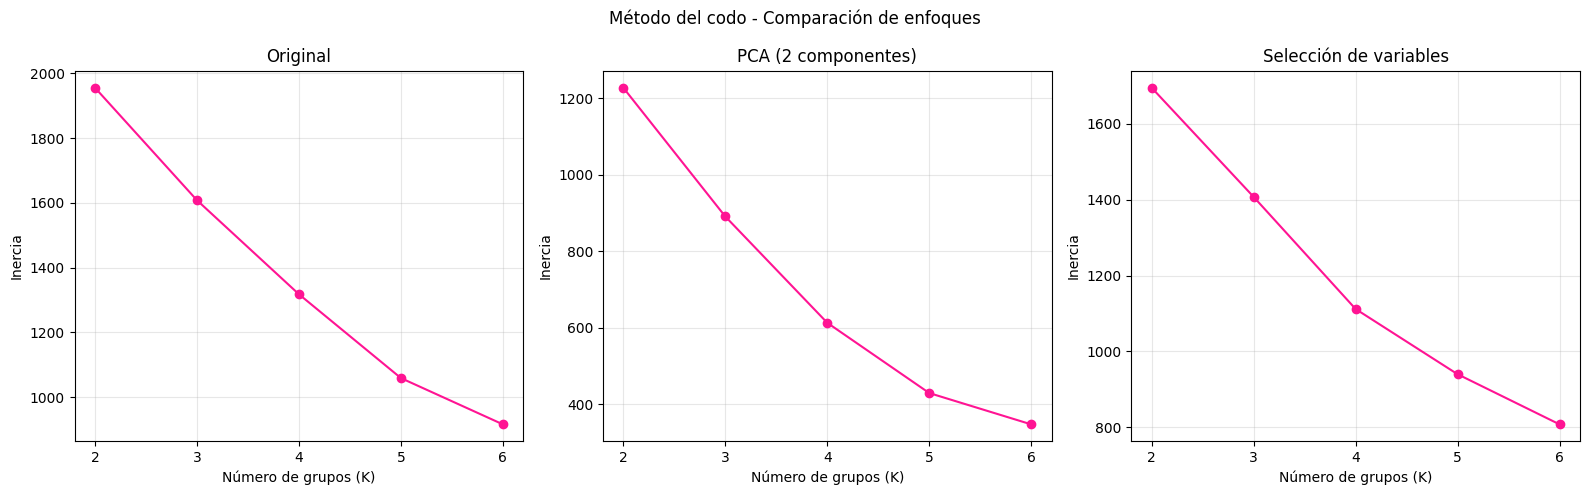

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nombre, datos) in zip(axes, conjuntos.items()):

    inercias = []

    for k in valores_k:
        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        modelo.fit(datos)
        inercias.append(modelo.inertia_)

    ax.plot(
        list(valores_k),
        inercias,
        marker="o",
        color="deeppink"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Número de grupos (K)")
    ax.set_ylabel("Inercia")
    ax.set_xticks(list(valores_k))
    ax.grid(alpha=0.3)

plt.suptitle("Método del codo - Comparación de enfoques")
plt.tight_layout()
plt.show()

In [27]:
tabla_comparativa = tabla_resultados.pivot(
    index="K",
    columns="Enfoque",
    values="Silhouette Score"
)

display(tabla_comparativa.round(4))

Enfoque,Original,PCA (2 componentes),Selección de variables
K,,,
2,0.5472,0.6362,0.6277
3,0.5483,0.6267,0.6064
4,0.3485,0.4888,0.4243
5,0.3690,0.4877,0.3643
6,0.3782,0.4594,0.3198


Al comparar los resultados, se observa que la reducción de dimensionalidad mediante PCA permitió obtener el mayor coeficiente Silhouette. Aunque la selección de variables también presentó un resultado favorable, PCA consiguió una mejor separación de los grupos.

Por otra parte, los datos originales presentaron valores inferiores, lo que sugiere que trabajar con los datos transformados puede facilitar la identificación de patrones de compra similares entre los clientes.

In [28]:
mejor_resultado = tabla_resultados.loc[
    tabla_resultados["Silhouette Score"].idxmax()
]

print("Mejor combinación encontrada:")
display(mejor_resultado.to_frame("Resultado"))

Mejor combinación encontrada:


,Resultado
Enfoque,PCA (2 componentes)
K,2
Inercia,1227.874021
Silhouette Score,0.63622


### Mejor combinación encontrada
- Enfoque: PCA (2 componentes).
- Número de grupos: K=2.
- Inercia: 1227.8740.
- Silhouette Score: 0.6362.
Esta combinación fue la mejor porque obtuvo el mayor coeficiente Silhouette entre todas las alternativas evaluadas. Por lo tanto, se considera la opción más adecuada para representar los grupos de clientes en este análisis.

#### Conclusión general del trabajo
El análisis permitió identificar patrones de compra entre los clientes mayoristas mediante técnicas de aprendizaje no supervisado. Inicialmente, se utilizaron seis variables relacionadas con el gasto en diferentes categorías de productos. Posteriormente, mediante PCA se logró representar el 72.46 % de la variabilidad de los datos en dos componentes, mientras que el análisis de correlación permitió reducir las variables a cinco.

Finalmente, se aplicó el algoritmo K-means utilizando los datos originales, los componentes principales y las variables seleccionadas. La mejor combinación fue PCA con dos componentes y K=2, que obtuvo un Silhouette Score de 0.6362. Esto indica que esta alternativa logró una mejor separación de los grupos frente a los otros enfoques evaluados.

En general, el ejercicio permitió reconocer la utilidad de reducir la dimensionalidad y comparar diferentes alternativas antes de elegir un modelo de agrupamiento.